In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import sys
import json

from pathlib import Path

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    ParameterGrid
)

sys.path.insert(0, str(Path("..").resolve()))

from src.train_models import create_models
from src.evaluate_models import evaluate_classifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [2]:
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
RESULT_DIR = Path("../reports/results")
FIGURE_DIR = Path("../reports/figures")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Directories configured successfully!")

Directories configured successfully!


In [3]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
)["label"]

X_val = pd.read_csv(DATA_DIR / "X_val.csv")

y_val = pd.read_csv(
    DATA_DIR / "y_val.csv"
)["label"]

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("\nValidation Features:", X_val.shape)
print("Validation Target:", y_val.shape)

Training Features: (140274, 42)
Training Target: (140274,)

Validation Features: (35067, 42)
Validation Target: (35067,)


In [4]:
models = create_models(
    X_train,
    random_state=RANDOM_STATE
)

for name in models:
    print(f"{name} created successfully!")

Logistic Regression created successfully!
Decision Tree created successfully!
Random Forest created successfully!


In [5]:
groups = pd.util.hash_pandas_object(
    X_train,
    index=False
).to_numpy()

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Group-aware 5-Fold CV configured!")

Group-aware 5-Fold CV configured!


In [13]:
lr_param_grid = {
    "classifier__C": [0.1, 1],
    "classifier__class_weight": [None, "balanced"]
}

In [14]:
dt_param_grid = {
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_leaf": [1, 5]
}

In [15]:
rf_param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [20, None]
}

In [16]:
param_grids = {
    "Logistic Regression": lr_param_grid,

    "Decision Tree": dt_param_grid,

    "Random Forest": rf_param_grid
}

total_combinations = 0

for name, grid in param_grids.items():

    combinations = len(list(ParameterGrid(grid)))

    total_combinations += combinations

    print(f"{name}: {combinations} combinations")

print("\nTotal Combinations:", total_combinations)

print("Total CV Training Operations:",
      total_combinations * 5)

Logistic Regression: 4 combinations
Decision Tree: 6 combinations
Random Forest: 4 combinations

Total Combinations: 14
Total CV Training Operations: 70


In [17]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [18]:
grid_search_results = {}
tuned_models = {}
tuning_summary = []

for name, model in models.items():

    print(f"\nTuning {name}...", flush=True)

    start_time = time.perf_counter()

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="f1",
        cv=cv,
        n_jobs=1,
        verbose=1,
        return_train_score=False,
        error_score="raise"
    )

    grid_search.fit(
        X_train,
        y_train,
        groups=groups
    )

    elapsed_time = time.perf_counter() - start_time

    grid_search_results[name] = grid_search
    tuned_models[name] = grid_search.best_estimator_

    best_index = grid_search.best_index_
    results = grid_search.cv_results_

    tuning_summary.append({
        "Model": name,
        "Best CV Accuracy":
            results["mean_test_accuracy"][best_index],

        "Best CV Precision":
            results["mean_test_precision"][best_index],

        "Best CV Recall":
            results["mean_test_recall"][best_index],

        "Best CV F1 Score":
            grid_search.best_score_,

        "Best CV ROC AUC":
            results["mean_test_roc_auc"][best_index],

        "Tuning Time (Seconds)": elapsed_time,

        "Best Parameters":
            str(grid_search.best_params_)
    })

    filename = (
        "tuned_"
        + name.lower().replace(" ", "_")
        + ".pkl"
    )

    joblib.dump(
        grid_search.best_estimator_,
        MODEL_DIR / filename,
        compress=3
    )

    print("Best Parameters:", grid_search.best_params_)
    print("Best F1 Score:", grid_search.best_score_)
    print(f"Time: {elapsed_time:.2f} seconds")
    print(f"Model saved: {filename}")

print("\nAll models tuned successfully!")


Tuning Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters: {'classifier__C': 1, 'classifier__class_weight': None}
Best F1 Score: 0.9538212864241103
Time: 217.83 seconds
Model saved: tuned_logistic_regression.pkl

Tuning Decision Tree...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5}
Best F1 Score: 0.9597771911373293
Time: 407.25 seconds
Model saved: tuned_decision_tree.pkl

Tuning Random Forest...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 100}
Best F1 Score: 0.9661129987304058
Time: 1800.74 seconds
Model saved: tuned_random_forest.pkl

All models tuned successfully!


In [19]:
tuning_summary_df = pd.DataFrame(
    tuning_summary
)

tuning_summary_df = tuning_summary_df.sort_values(
    by="Best CV F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    tuning_summary_df.drop(
        columns=["Best Parameters"]
    ).round(4)
)

,Model,Best CV Accuracy,Best CV Precision,Best CV Recall,Best CV F1 Score,Best CV ROC AUC,Tuning Time (Seconds)
0,Random Forest,0.9534,0.9567,0.9757,0.9661,0.9922,1800.7410
1,Decision Tree,0.9444,0.9455,0.9745,0.9598,0.9875,407.2545
2,Logistic Regression,0.9349,0.9220,0.9879,0.9538,0.9839,217.8297


In [20]:
for name, search in grid_search_results.items():

    print("=" * 50)
    print(name)
    print("=" * 50)

    for parameter, value in search.best_params_.items():

        parameter = parameter.replace(
            "classifier__", ""
        )

        print(f"{parameter}: {value}")

    print()

Logistic Regression
C: 1
class_weight: None

Decision Tree
max_depth: 10
min_samples_leaf: 5

Random Forest
max_depth: None
n_estimators: 100



In [21]:
tuned_evaluation_results = []

for name, model in tuned_models.items():

    result = evaluate_classifier(
        model,
        X_val,
        y_val
    )

    result["Model"] = name

    tuned_evaluation_results.append(result)

    print(f"{name} evaluated successfully!")

tuned_performance_df = pd.DataFrame(
    tuned_evaluation_results
)

tuned_performance_df = tuned_performance_df[
    ["Model"] + [
        col for col in tuned_performance_df.columns
        if col != "Model"
    ]
]

display(tuned_performance_df.round(4))

Logistic Regression evaluated successfully!
Decision Tree evaluated successfully!
Random Forest evaluated successfully!


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,True Negative,False Positive,False Negative,True Positive,False Negative Rate,False Positive Rate
0,Logistic Regression,0.9352,0.9219,0.9886,0.9541,0.9845,9200,2000,272,23595,0.0114,0.1786
1,Decision Tree,0.9450,0.9433,0.9780,0.9604,0.9889,9798,1402,525,23342,0.0220,0.1252
2,Random Forest,0.9537,0.9572,0.9757,0.9663,0.9928,10158,1042,580,23287,0.0243,0.0930


In [22]:
baseline_df = pd.read_csv(
    RESULT_DIR / "model_performance.csv"
)

metrics = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC",
    "False Positive",
    "False Negative"
]

comparison_df = baseline_df[metrics].merge(
    tuned_performance_df[metrics],

    on="Model",

    suffixes=("_Baseline", "_Tuned")
)

display(comparison_df.round(4))

,Model,Accuracy_Baseline,Precision_Baseline,Recall_Baseline,F1 Score_Baseline,ROC AUC_Baseline,False Positive_Baseline,False Negative_Baseline,Accuracy_Tuned,Precision_Tuned,Recall_Tuned,F1 Score_Tuned,ROC AUC_Tuned,False Positive_Tuned,False Negative_Tuned
0,Random Forest,0.9537,0.9572,0.9757,0.9663,0.9928,1042,580,0.9537,0.9572,0.9757,0.9663,0.9928,1042,580
1,Decision Tree,0.9428,0.9594,0.9565,0.9579,0.9365,966,1039,0.9450,0.9433,0.9780,0.9604,0.9889,1402,525
2,Logistic Regression,0.9352,0.9219,0.9886,0.9541,0.9845,2000,272,0.9352,0.9219,0.9886,0.9541,0.9845,2000,272


In [23]:
comparison_df["Accuracy Improvement (%)"] = (
    comparison_df["Accuracy_Tuned"] -
    comparison_df["Accuracy_Baseline"]
) * 100

comparison_df["Recall Improvement (%)"] = (
    comparison_df["Recall_Tuned"] -
    comparison_df["Recall_Baseline"]
) * 100

comparison_df["F1 Improvement (%)"] = (
    comparison_df["F1 Score_Tuned"] -
    comparison_df["F1 Score_Baseline"]
) * 100

comparison_df["False Negatives Reduced"] = (
    comparison_df["False Negative_Baseline"] -
    comparison_df["False Negative_Tuned"]
)

display(comparison_df[[
    "Model",
    "Accuracy Improvement (%)",
    "Recall Improvement (%)",
    "F1 Improvement (%)",
    "False Negatives Reduced"
]].round(4))

,Model,Accuracy Improvement (%),Recall Improvement (%),F1 Improvement (%),False Negatives Reduced
0,Random Forest,0.0000,0.0000,0.0000,0
1,Decision Tree,0.2224,2.1536,0.2427,514
2,Logistic Regression,0.0000,0.0000,0.0000,0


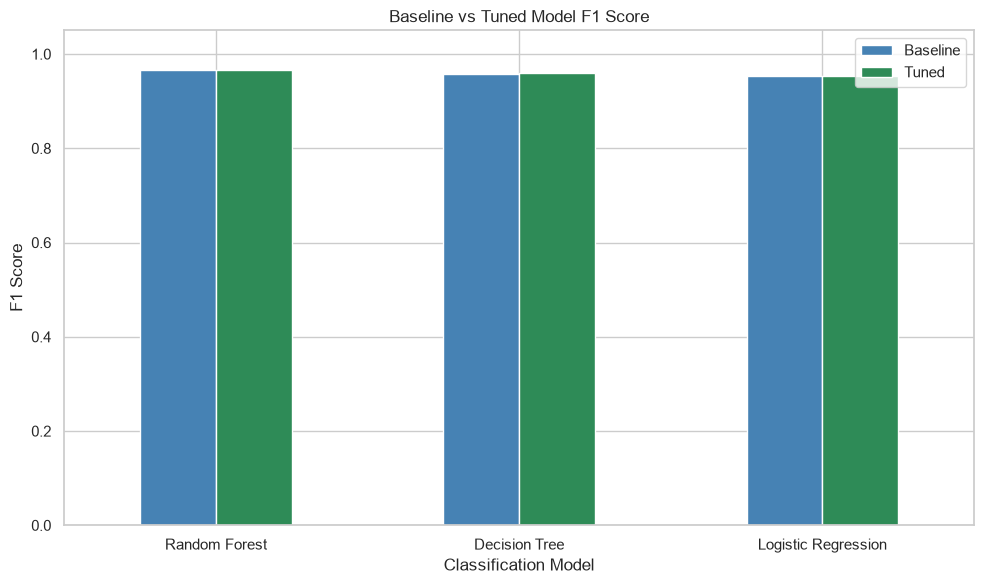

In [24]:
comparison_df.set_index("Model")[[
    "F1 Score_Baseline",
    "F1 Score_Tuned"
]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "seagreen"]
)

plt.title("Baseline vs Tuned Model F1 Score")
plt.xlabel("Classification Model")
plt.ylabel("F1 Score")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(["Baseline", "Tuned"])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_vs_tuned_f1.png",
    dpi=300
)

plt.show()

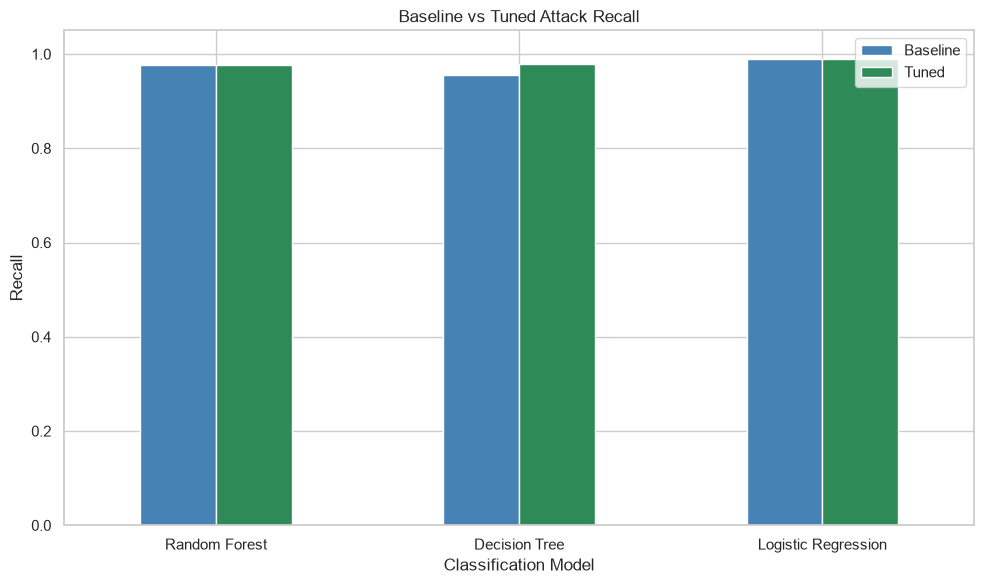

In [25]:
comparison_df.set_index("Model")[[
    "Recall_Baseline",
    "Recall_Tuned"
]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "seagreen"]
)

plt.title("Baseline vs Tuned Attack Recall")
plt.xlabel("Classification Model")
plt.ylabel("Recall")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(["Baseline", "Tuned"])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_vs_tuned_recall.png",
    dpi=300
)

plt.show()

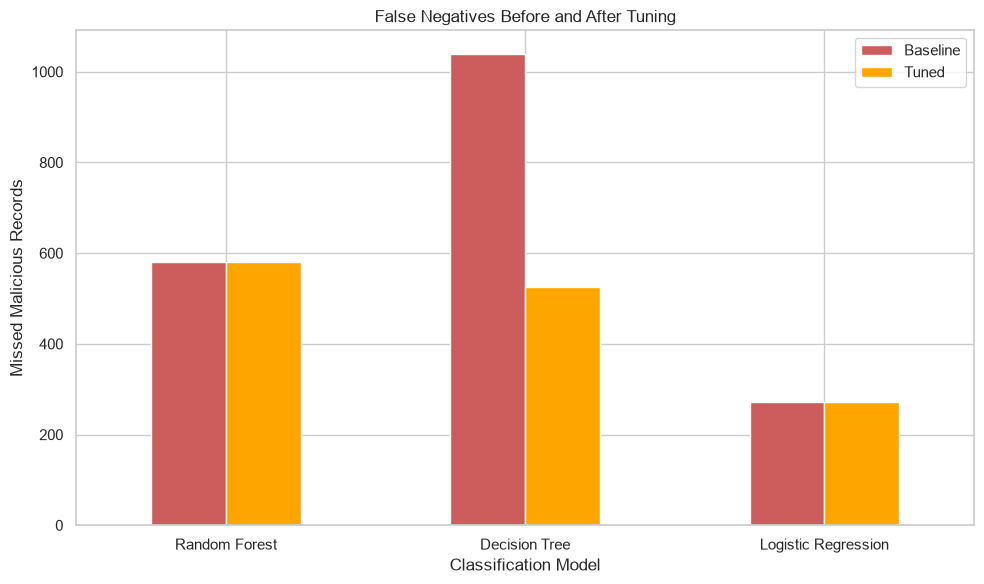

In [26]:
comparison_df.set_index("Model")[[
    "False Negative_Baseline",
    "False Negative_Tuned"
]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["indianred", "orange"]
)

plt.title("False Negatives Before and After Tuning")
plt.xlabel("Classification Model")
plt.ylabel("Missed Malicious Records")

plt.xticks(rotation=0)

plt.legend(["Baseline", "Tuned"])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_vs_tuned_fn.png",
    dpi=300
)

plt.show()

In [27]:
tuned_model_filenames = {
    "Logistic Regression":
        "tuned_logistic_regression.pkl",

    "Decision Tree":
        "tuned_decision_tree.pkl",

    "Random Forest":
        "tuned_random_forest.pkl"
}

for name, model in tuned_models.items():

    file_path = MODEL_DIR / tuned_model_filenames[name]

    joblib.dump(
        model,
        file_path,
        compress=3
    )

    print(f"{name} saved successfully!")

Logistic Regression saved successfully!
Decision Tree saved successfully!
Random Forest saved successfully!


In [28]:
best_parameters = {}

for name, search in grid_search_results.items():

    best_parameters[name] = search.best_params_

with open(
    RESULT_DIR / "best_hyperparameters.json",
    "w"
) as file:

    json.dump(
        best_parameters,
        file,
        indent=4
    )

print("Best hyperparameters saved successfully!")

Best hyperparameters saved successfully!


In [29]:
for name, search in grid_search_results.items():

    results_df = pd.DataFrame(
        search.cv_results_
    )

    filename = (
        name.lower().replace(" ", "_")
        + "_grid_search_results.csv"
    )

    results_df.to_csv(
        RESULT_DIR / filename,
        index=False
    )

    print(f"{filename} saved successfully!")

logistic_regression_grid_search_results.csv saved successfully!
decision_tree_grid_search_results.csv saved successfully!
random_forest_grid_search_results.csv saved successfully!


In [30]:
tuning_summary_df.to_csv(
    RESULT_DIR / "hyperparameter_tuning_summary.csv",
    index=False
)

tuned_performance_df.to_csv(
    RESULT_DIR / "tuned_model_performance.csv",
    index=False
)

comparison_df.to_csv(
    RESULT_DIR / "baseline_vs_tuned_comparison.csv",
    index=False
)

print("All tuning reports saved successfully!")

All tuning reports saved successfully!
